## Figure 3
Top 15 Total deaths by ISO 

In [4]:
import sys
from pathlib import Path

PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "utils").is_dir()
)
sys.path.insert(0, str(PROJECT_ROOT))

import os
from datetime import datetime, UTC
from dotenv import find_dotenv, load_dotenv
import xarray as xr
import xvec

import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.ticker import MultipleLocator
import cartopy.crs as ccrs

from utils import analysis_utils
from utils import isku_utils
from utils import plotting_utils
from utils import stats_utils

import importlib

importlib.reload(analysis_utils)
importlib.reload(isku_utils)
importlib.reload(plotting_utils)

<module 'utils.plotting_utils' from '/home/emily_zuetell/projects/poreallas/utils/plotting_utils.py'>

In [5]:
load_dotenv(
    find_dotenv("october_local.env", raise_error_if_not_found=True), override=True
)

EFFECTS_URI = os.environ["POREALLAS_EFFECTS_URI"]
IMPACT_REGION_POLYGONS = os.environ["POREALLAS_REGIONS_POLYGONS_URI"]
SOCIOECONOMICS_URI = os.environ["POREALLAS_SOCIOECONOMICS_URI"]

In [6]:
# Baseline period for Impact
effect = xr.open_datatree(EFFECTS_URI, consolidated=False)
BASELINE_PERIOD = analysis_utils.get_baseline_period(effect, years=30)
# Define Forecast Months
FC_MONTHS = [10, 11, 12, 1, 2, 3]
FC_PERIOD = slice("2026-10-01", "2027-03-31")

config = analysis_utils.ImpactConfig(
    version=f"v{datetime.now(tz=UTC):%y%m%d}",
    baseline_period=BASELINE_PERIOD,
    polygons_path=os.environ["POREALLAS_REGIONS_POLYGONS_URI"],
    socioeconomics_path=os.environ["POREALLAS_SOCIOECONOMICS_URI"],
    rate=False,
    age_weight = True,
    months=FC_MONTHS,
    hotonly="hotonly",
    dims=["number", "sample"],
)

In [7]:
# Compute impact: forecast - baseline
impact = analysis_utils.compute_impact(
    effect.chunk({dim: -1 for dim in config.dims}),
    config,
    ensemble=True,
)
# Use only the defined 6-months
impact = impact.sel(month=config.months)

In [8]:
# Aggregate Impact Regions to group_level
group_level = 'ISO' #IR: Impact region, # ADM1: State level, # ISO: Country level
impact, merge_key, base_cols = analysis_utils.aggregate_impact(impact, config, group_level)

In [9]:
def fetch_country_boundaries():
    url = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson"
    return gpd.read_file(url)[["NAME", "ADM0_A3", "geometry"]]

def join_to_countries(gdf, countries):
    return gpd.sjoin(gdf.to_crs(countries.crs), countries, how="left", predicate="intersects")

countries = fetch_country_boundaries()

In [10]:
# Ordered by Population In Need (Projected March 2027)
df_fewsnet = ['Sudan', 'Pakistan', 'Nigeria', 'Dem. Rep. Congo', 
              'Yemen', 'Afghanistan', 'South Sudan',
              'Syria', 'Somalia', 'Colombia', 'Haiti',
              'Zimbabwe', 'Uganda', 'Kenya', 'Guatemala', 
              'Venezuela', 'Ukraine', 'Madagascar', 'Malawi',
              'Mozambique', 'Chad', 'Niger', 'Cameroon', 'Lebanon',
              'Angola', 'Sri Lanka', 'Burkina Faso', 'Nepal',
              'Central African Republic', 'Zambia', 'Mali', 'Burundi',
              'Honduras', 'Togo', 'Lesotho']

In [11]:
total = impact.sum(dim='month')

df = xr.Dataset({
    'impact': total.mean(dim=config.dims),
    'p17': total.quantile(0.17, dim=config.dims).drop_vars('quantile'),
    'p83': total.quantile(0.83, dim=config.dims).drop_vars('quantile'),
}).to_dataframe().reset_index()

df = df.drop(columns = ['year'])
iso_to_name = countries.set_index("ADM0_A3")["NAME"].to_dict()
df["country"] = df["ISO"].map(iso_to_name)
# S. Sudan
df.loc[df['ISO'] == 'SSD', 'country'] = 'South Sudan'

/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


In [12]:
rank_map = {country: i + 1 for i, country in enumerate(df_fewsnet)}
df["fewsnet_rank"] = df["country"].map(rank_map)

In [13]:
income = pd.read_csv("../data/base/income_class_2025.csv")

In [14]:
merged = df.merge(income, left_on="country", right_on="Economy", how="inner")

In [15]:
merged.sort_values('impact', ascending = False).head(10)

,ISO,impact,p17,p83,country,fewsnet_rank,Economy,Code,Income group
148,NGA,56099.353087,23756.112017,90874.147994,Nigeria,3.0,Nigeria,NGA,Lower middle income
92,IND,55213.176774,12732.140742,100433.744923,India,NaN,India,IND,Lower middle income
90,IDN,29278.992211,8685.268783,55098.203269,Indonesia,NaN,Indonesia,IDN,Upper middle income
28,BRA,19478.485184,6949.583326,34655.381531,Brazil,NaN,Brazil,BRA,Upper middle income
174,SDN,14659.333157,6793.000070,23325.698447,Sudan,1.0,Sudan,SDN,Low income
197,THA,12181.571313,5401.693759,19228.009430,Thailand,NaN,Thailand,THA,Upper middle income
195,TCD,11349.404042,5121.259595,17746.887488,Chad,21.0,Chad,TCD,Low income
161,PHL,11070.826090,2636.099788,21150.246462,Philippines,NaN,Philippines,PHL,Lower middle income
146,NER,8415.471526,3097.728221,13598.356782,Niger,22.0,Niger,NER,Low income
216,VNM,8333.443374,3026.986940,14456.810676,Vietnam,NaN,Vietnam,VNM,Lower middle income


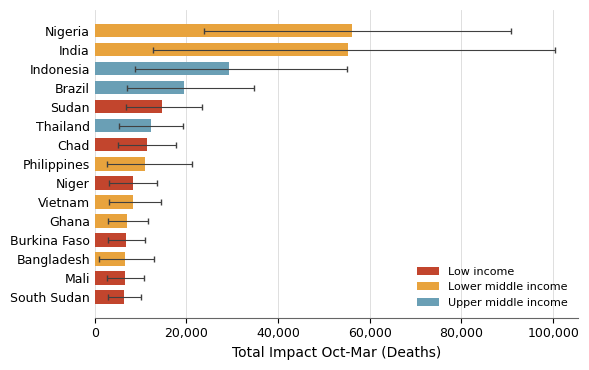

In [16]:
from matplotlib.patches import Patch

top = merged.sort_values('impact', ascending=False).head(15)
y = np.arange(len(top))
in_top10 = ~(top['fewsnet_rank'] <= 30).values
# Error Bars (Central 66% Estimate)
xerr = np.vstack([
    top['impact'] - top['p17'],
    top['p83'] - top['impact'],
]).clip(min=0)

income_colors = {
    'Low income': '#C2452D',
    'Lower middle income': '#E8A33D',
    'Upper middle income': '#6A9FB5',
    'High income': '#9AA5B1',
}
colors = top['Income group'].map(income_colors).fillna('#CCCCCC')

fig, ax = plt.subplots(figsize=(6, 3.8))
bars = ax.barh(y, top['impact'], color=colors, height=0.7,
               xerr=xerr, error_kw=dict(ecolor='0.25', lw=0.8, capsize=2))

ax.set_yticks(y, top['country'], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel('Total Impact Oct-Mar (Deaths)', fontsize=10)
ax.xaxis.set_major_formatter('{x:,.0f}')
ax.tick_params(axis='x', labelsize=9)
ax.tick_params(axis='y', length=0)

ax.grid(axis='x', color='0.85', lw=0.6)
ax.set_axisbelow(True)
for side in ('top', 'right', 'left'):
    ax.spines[side].set_visible(False)
ax.spines['bottom'].set_color('0.4')

handles = [Patch(facecolor=c, label=g) for g, c in income_colors.items()
           if g in top['Income group'].values]
ax.legend(handles=handles, frameon=False, fontsize=8, loc='lower right')

fig.tight_layout()
fig.savefig(f'v261028_fig03_impact_bar.png', dpi=300, bbox_inches='tight')